we are going to implement Quantum Phase Estimation using Qiskit. The goal is to estimate a known quantum phase by encoding it into a counting register, applying controlled unitary operations, and then using the inverse Quantum Fourier Transform to convert that phase information into a measurable binary result.

In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np

In [3]:
phase = 1 / 8
num_counting_qubits = 3

print(f"Target phase: {phase}")
print(f"Counting qubits: {num_counting_qubits}")

Target phase: 0.125
Counting qubits: 3


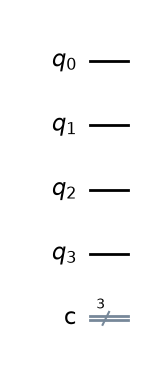

In [4]:
target_qubit = num_counting_qubits

qpe_circuit = QuantumCircuit(
    num_counting_qubits + 1,
    num_counting_qubits
)

qpe_circuit.draw("mpl")

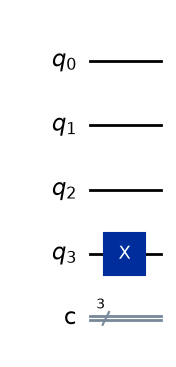

In [5]:
qpe_circuit.x(target_qubit)

qpe_circuit.draw("mpl")

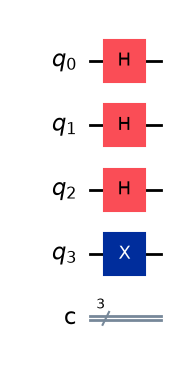

In [6]:
for qubit in range(num_counting_qubits):
    qpe_circuit.h(qubit)

qpe_circuit.draw("mpl")

In [7]:
theta = 2 * np.pi * phase

print(f"Phase rotation angle: {theta:.4f} radians")

Phase rotation angle: 0.7854 radians


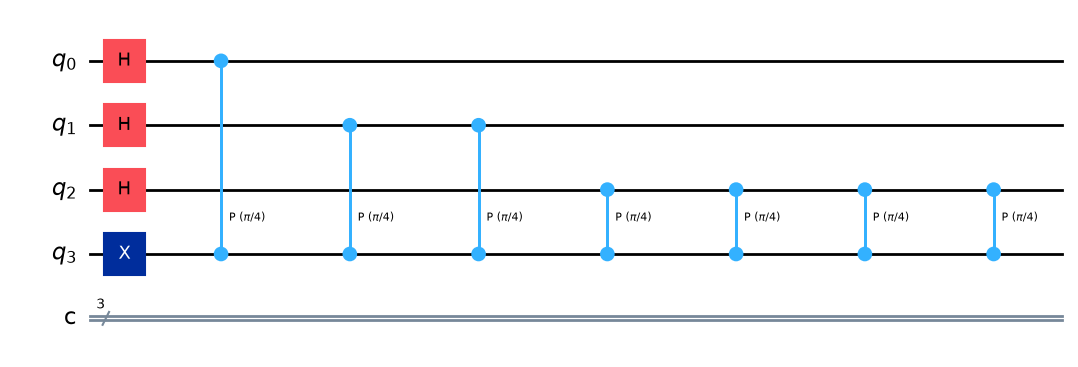

In [8]:
for qubit in range(num_counting_qubits):
    repetitions = 2 ** qubit

    for _ in range(repetitions):
        qpe_circuit.cp(theta, qubit, target_qubit)

qpe_circuit.draw("mpl")

In [9]:
def inverse_qft(n):
    circuit = QuantumCircuit(n)

    for qubit in range(n // 2):
        circuit.swap(qubit, n - qubit - 1)

    for target in reversed(range(n)):
        for control in reversed(range(target + 1, n)):
            angle = -np.pi / (2 ** (control - target))
            circuit.cp(angle, control, target)

        circuit.h(target)

    return circuit

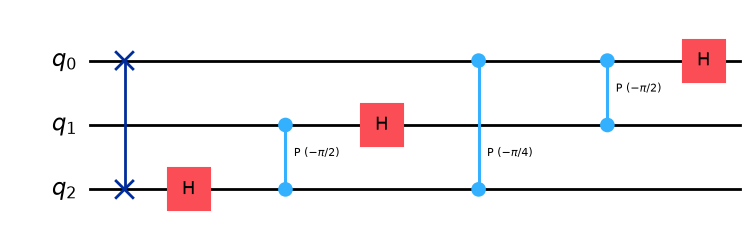

In [10]:
iqft = inverse_qft(num_counting_qubits)

iqft.draw("mpl")

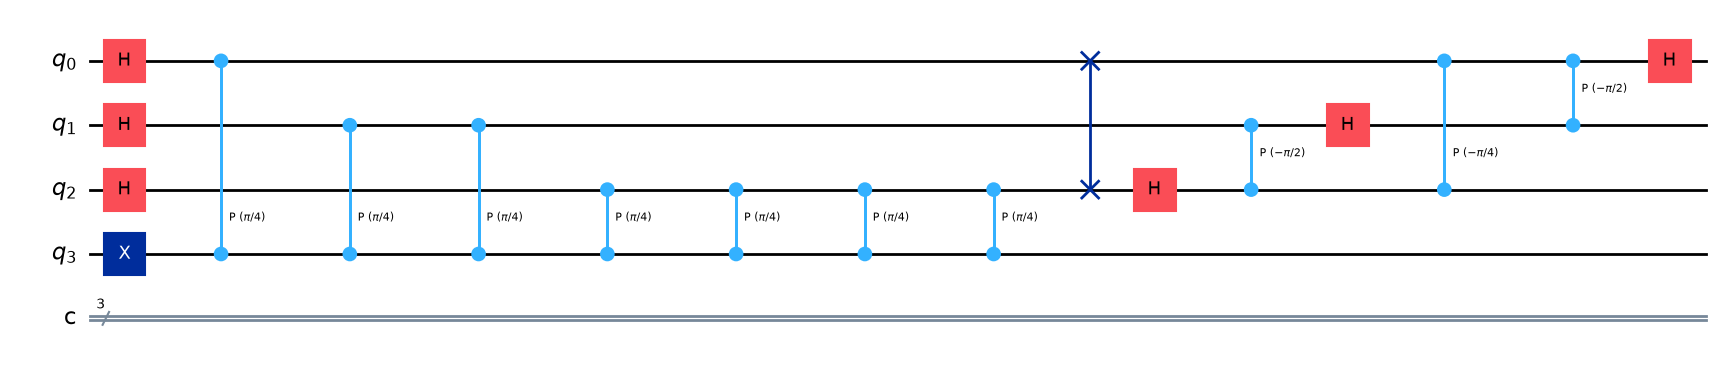

In [11]:
qpe_circuit.compose(
    iqft,
    qubits=range(num_counting_qubits),
    inplace=True
)

qpe_circuit.draw("mpl")

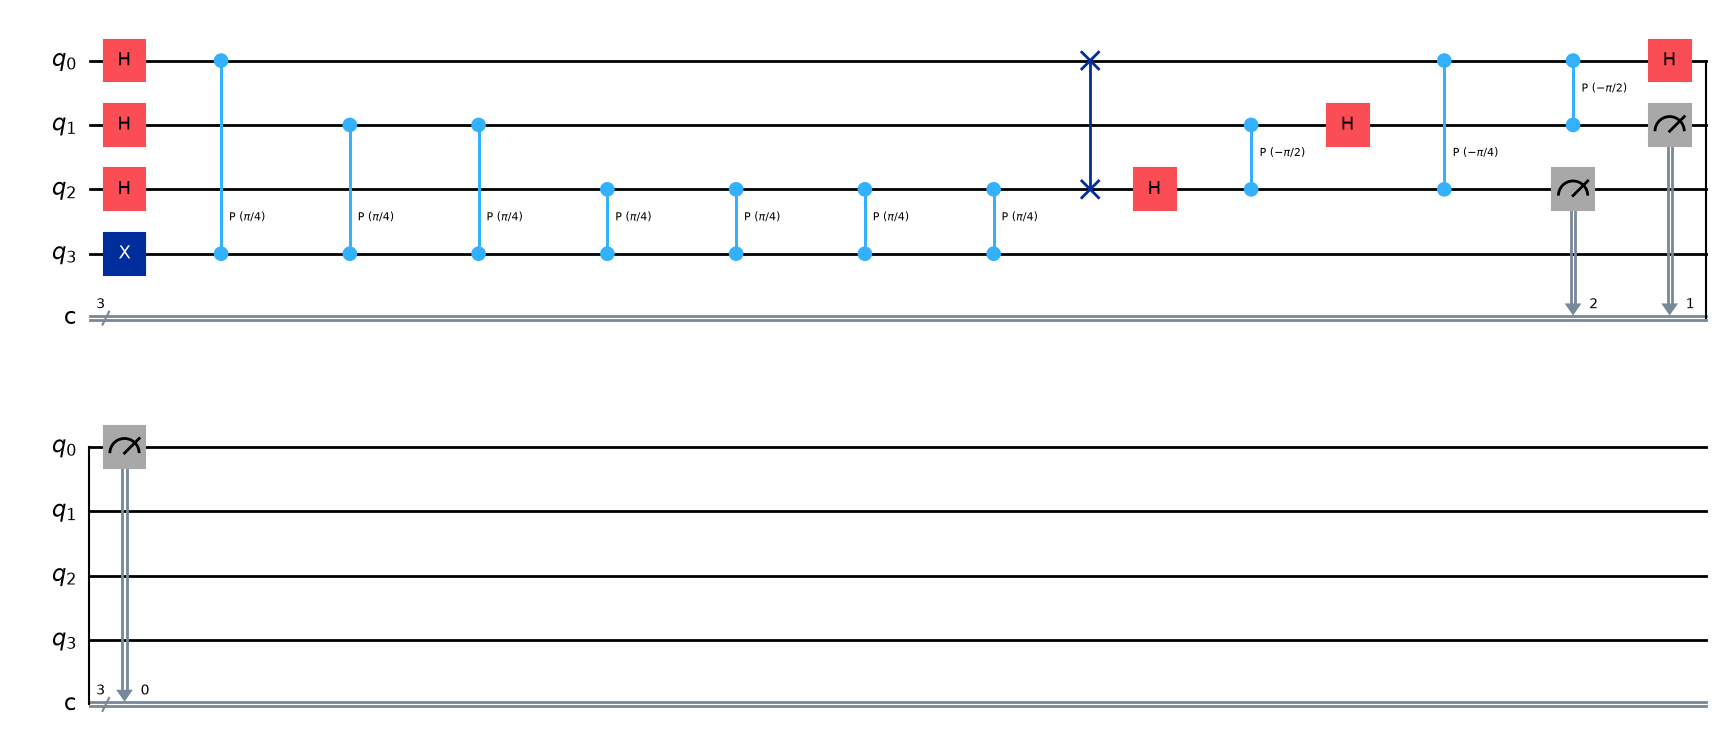

In [12]:
qpe_circuit.measure(
    range(num_counting_qubits),
    range(num_counting_qubits)
)

qpe_circuit.draw("mpl")

In [13]:
simulator = AerSimulator()

In [14]:
result = simulator.run(
    qpe_circuit,
    shots=1000
).result()

counts = result.get_counts()

print(counts)

{'010': 224, '011': 221, '001': 398, '101': 137, '100': 20}


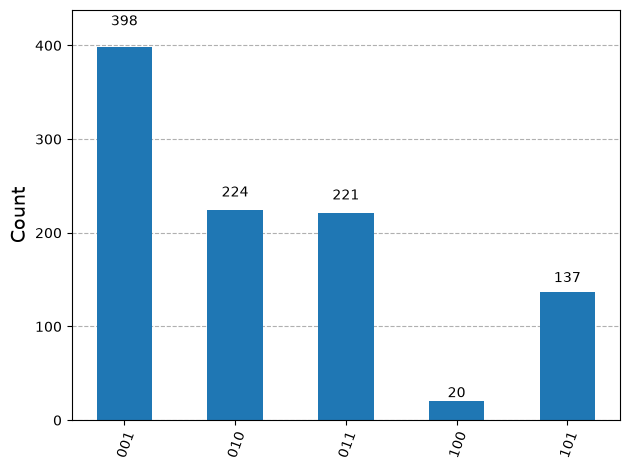

In [15]:
plot_histogram(counts)

In [16]:
measured_state = max(counts, key=counts.get)

print(f"Most likely measured state: {measured_state}")

Most likely measured state: 001


In [17]:
measured_integer = int(measured_state, 2)

estimated_phase = measured_integer / (2 ** num_counting_qubits)

print(f"Measured integer: {measured_integer}")
print(f"Estimated phase: {estimated_phase}")
print(f"Actual phase: {phase}")

Measured integer: 1
Estimated phase: 0.125
Actual phase: 0.125


In [18]:
error = abs(phase - estimated_phase)

print(f"Phase estimation error: {error:.6f}")

Phase estimation error: 0.000000


In [19]:
test_phase = 3 / 8

print(f"New phase: {test_phase}")
print(f"Binary representation: 0.011")

New phase: 0.375
Binary representation: 0.011
